# 01 · Cohort extraction

Turns the MIMIC-IV tables into one patient-level design matrix, and — the point
of this notebook — **proves the label is honest** before anything is trained on
it.

## Cohort definition

| | |
|---|---|
| Population | adults (≥18) admitted to an ICU |
| Unit | **first ICU stay only**, one row per `subject_id` |
| Inclusion | stay lasts at least `min_los_hours` |
| Feature window | `[intime, intime + obs_window_hours)` |
| Label | in-hospital mortality (`hospital_expire_flag`) |

One stay per patient is not just tidiness: it makes the train/val/test split
exact at the patient level, so no patient can appear on both sides of it.

## The four leakage controls

A first-24h mortality model is easy to make look excellent by accident. The
ETL enforces four rules, and this notebook asserts each one rather than
trusting the docstring:

1. **Window closure** — every event aggregated is timestamped strictly inside
   the observation window. No aggregate reaches past `intime + obs_window`.
2. **Deaths inside the window are dropped** — a patient who dies at hour 12 of
   a 24 h window has their outcome partly *inside* their own features. Keeping
   them makes the task trivially easy for the wrong reason.
3. **Comorbidities from prior admissions only** — `diagnoses_icd` holds billing
   codes assigned at *discharge*, so this admission's codes encode this
   admission's outcome. Only admissions closing before `intime` contribute.
   This is the single biggest leak in naive MIMIC pipelines.
4. **One stay per patient** — no patient straddles two splits.

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv, mimic_concepts as mc

cfg = mimic_cfg()
root = mimic_iv.find_root(RAW)
d = cfg["data"]
print("observation window : %g h" % d["obs_window_hours"])
print("minimum stay       : %g h" % d["min_los_hours"])
print("blocks             :", d["blocks"])
print("row signature      :", mimic_iv.row_signature(cfg))
print("cohort signature   :", mimic_iv.cohort_signature(cfg))

observation window : 24 h
minimum stay       : 28 h
blocks             : ['demographics', 'comorbidity', 'labs', 'vitals', 'treatment']
row signature      : 4c8f7e43b8
cohort signature   : 22b41c5f24


## Attrition

Every exclusion is reported as a count so the cohort is reconstructible from
this table alone.

In [2]:
base, steps = mimic_iv._base_cohort(root, cfg)
att = pd.DataFrame(steps, columns=["step", "n"])
att["dropped"] = att["n"].shift().sub(att["n"]).fillna(0).astype(int)
print(att.to_string(index=False))
print(f"\nfinal cohort: {len(base):,} patients, "
      f"in-hospital mortality {base['label'].mean():.4f}")

                   step     n  dropped
              icu stays 94458        0
 first stay per patient 65366    29092
                  adult 65366        0
             los >= 28h 46776    18590
      died after window 46705       71
discharged after window 46651       54

final cohort: 46,651 patients, in-hospital mortality 0.1102


A ~11% mortality rate is in the expected range for a first-24h adult ICU
cohort. Two sanity checks on that number:

- Much *higher* would suggest the early-death exclusion is not firing.
- Much *lower* would suggest the `min_los` filter is cutting the sick
  disproportionately — it does cut them somewhat by construction, which is a
  known selection effect of any fixed-window ICU task and is worth stating in
  the write-up rather than hiding.

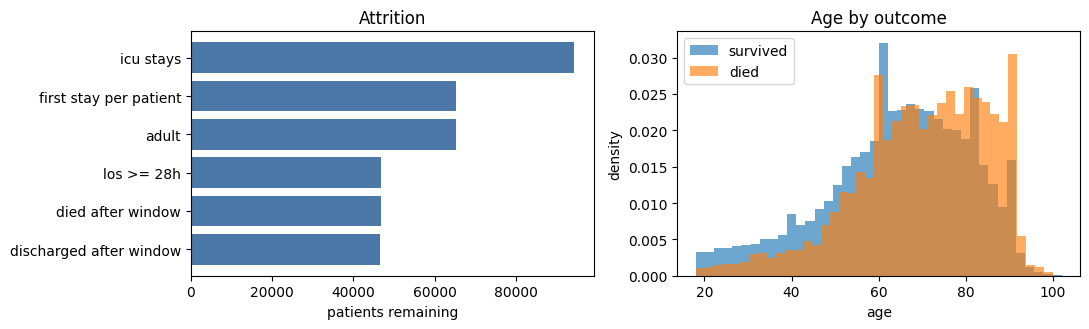

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].barh(att["step"][::-1], att["n"][::-1], color="#4C78A8")
ax[0].set_xlabel("patients remaining"); ax[0].set_title("Attrition")
for s, c in [(0, "survived"), (1, "died")]:
    ax[1].hist(base.loc[base["label"] == s, "age"], bins=40, alpha=.65, label=c, density=True)
ax[1].set_xlabel("age"); ax[1].set_ylabel("density"); ax[1].legend(); ax[1].set_title("Age by outcome")
plt.tight_layout(); plt.show()

## Leakage control 2 and 4 — assert directly on the cohort table

In [4]:
w = base["window_end"]

# 4. one row per patient
assert base["subject_id"].is_unique, "a patient appears more than once"
print("one stay per patient      OK  (%d unique subject_ids)" % base["subject_id"].nunique())

# 2. nobody died inside their own feature window
died_in_window = base["deathtime"].notna() & (base["deathtime"] <= w)
assert not died_in_window.any(), f"{died_in_window.sum()} deaths inside the window"
print("no death inside window    OK")

# and nobody was discharged inside it either -- their window is not observable
assert (base["dischtime"] > w).all(), "discharge inside the observation window"
print("no discharge inside window OK")

# the window is fully covered by the stay
assert (base["los_hours"] >= d["obs_window_hours"]).all()
print("window covered by stay    OK  (min LOS %.1f h)" % base["los_hours"].min())

one stay per patient      OK  (46651 unique subject_ids)
no death inside window    OK
no discharge inside window OK
window covered by stay    OK  (min LOS 28.0 h)


## Build the feature blocks

Each block is cached to disk the moment it is built, keyed on the *row*
signature — the fields that decide which patients are in the cohort, not which
blocks are enabled. Enabling one more block therefore reuses the multi-GB scans
already done for the others.

This matters because `labs` and `vitals` each cost a full scan of an 18 GB and
a 42 GB CSV. On a hosted kernel with a wall-clock session limit, losing those
to an unrelated failure later in the pipeline is expensive.

In [5]:
t0 = time.time()
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=True)
print(f"\nX {X_raw.shape}  y {y.shape}  prevalence {y.mean():.4f}  [{time.time()-t0:.1f}s]")

[mimic] building cohort from /kaggle/input/datasets/akshaybe/updated-mimic-iv/mimic-iv-3.1


  icu stays                      94,458
  first stay per patient         65,366
  adult                          65,366
  los >= 28h                     46,776
  died after window              46,705
  discharged after window        46,651
  [demographics] cached (33 cols)
  [comorbidity] cached (19 cols)
  [labs] cached (168 cols)
  [vitals] cached (84 cols)
  [treatment] cached (27 cols)
  [vitals] present for 17,663 / 46,651 patients (37.9%)
  dropped 28,988 patients lacking a required block -> 17,663 remain


[mimic] wrote /kaggle/working/processed/cohort_22b41c5f24.csv.gz  (17,663 patients, 331 features, prevalence 0.108)

X (17663, 331)  y (17663,)  prevalence 0.1078  [15.2s]


In [6]:
blocks = pd.DataFrame([
    {"block": k, "cols": len(v), "first": v[0], "last": v[-1]}
    for k, v in meta["views"].items()])
blocks["missing_%"] = [
    100 * np.isnan(X_raw[:, v]).mean() for v in meta["views"].values()]
print(blocks.to_string(index=False))
print(f"\ntotal features: {X_raw.shape[1]}")
print(f"overall missingness: {100*np.isnan(X_raw).mean():.1f}%")

       block  cols  first  last  missing_%
demographics    33      0    32   0.000000
 comorbidity    19     33    51   0.000000
        labs   168     52   219  21.693316
      vitals    84    220   303  14.621970
   treatment    27    304   330   0.000839

total features: 331
overall missingness: 14.7%


Missingness is left as `NaN` here on purpose. Imputation happens later in
`data_prep.impute_and_scale`, fit on the **training split only**, and the
missingness pattern itself is kept as indicator columns — in the ICU a lab that
was not drawn is a clinical decision, not an absence of information.

## Leakage control 1 — window closure, verified against the raw table

The aggregation SQL filters on `charttime < window_end`, but that is the thing
being tested, so re-derive it independently: sample some patients, pull their
raw events, and confirm nothing outside the window contributed.

In [7]:
import duckdb

sample = base.sample(min(300, len(base)), random_state=0)[
    ["stay_id", "intime", "window_end"]].copy()
con = duckdb.connect(); con.register("s", sample)
path = mimic_iv.table_path(root, "icu/chartevents.csv")
ids = ", ".join(str(i) for i in sorted(mc.CHART_ITEMS))

out = con.execute(f"""
    SELECT count(*) AS n_in_window,
           sum(CASE WHEN e.charttime >= s.window_end THEN 1 ELSE 0 END) AS n_after,
           sum(CASE WHEN e.charttime <  s.intime     THEN 1 ELSE 0 END) AS n_before
    FROM read_csv_auto('{path}', ignore_errors=true) e
    JOIN s ON e.stay_id = s.stay_id
    WHERE e.itemid IN ({ids}) AND e.valuenum IS NOT NULL
      AND e.charttime >= s.intime AND e.charttime < s.window_end
""").fetch_df()
con.close()
print(out.to_string(index=False))
assert out["n_after"].iloc[0] == 0 and out["n_before"].iloc[0] == 0
print("\nwindow closure OK — every aggregated event lies inside [intime, window_end)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

 n_in_window  n_after  n_before
       23087      0.0       0.0

window closure OK — every aggregated event lies inside [intime, window_end)


## Leakage control 3 — comorbidities predate the ICU stay

In [8]:
con = duckdb.connect()
diag_p = mimic_iv.table_path(root, "hosp/diagnoses_icd.csv")
adm_p  = mimic_iv.table_path(root, "hosp/admissions.csv")
con.register("c", base[["subject_id", "intime"]])

# How much of the raw diagnosis table would a naive pipeline have used? Every
# row whose admission had not closed before intime is outcome-contaminated.
counts = con.execute(f"""
    SELECT
      sum(CASE WHEN a.dischtime <  c.intime THEN 1 ELSE 0 END) AS usable_prior,
      sum(CASE WHEN a.dischtime >= c.intime THEN 1 ELSE 0 END) AS contaminated
    FROM read_csv_auto('{diag_p}') d
    JOIN read_csv_auto('{adm_p}') a USING (subject_id, hadm_id)
    JOIN c ON c.subject_id = d.subject_id
""").fetch_df()
con.close()
print(counts.to_string(index=False))
share = counts["contaminated"].iloc[0] / counts.sum(axis=1).iloc[0]
print(f"\n{share:.1%} of this cohort's diagnosis rows are outcome-contaminated "
      f"and are excluded by control 3")

# Independent check: a patient with no closed prior admission cannot carry any
# comorbidity flag.
# `n_prior_admissions` lives in the comorbidity block but does not carry the
# cci_ prefix, so name the columns explicitly rather than by prefix.
flag_cols = [c for c in names if c.startswith("cci_") and c != "cci_score"]
cci = flag_cols + ["cci_score", "n_prior_admissions"]
Xc = pd.DataFrame(X_raw[:, [names.index(c) for c in cci]], columns=cci)
no_history = Xc["n_prior_admissions"].to_numpy() == 0
assert Xc.loc[no_history, flag_cols].to_numpy().sum() == 0, \
    "comorbidity flagged for a patient with no prior admission"
print(f"\npatients with no prior admission: {no_history.mean()*100:.1f}%")
print("none of them carries a comorbidity flag  OK")

 usable_prior  contaminated
     503022.0     1969675.0

79.7% of this cohort's diagnosis rows are outcome-contaminated and are excluded by control 3

patients with no prior admission: 68.3%
none of them carries a comorbidity flag  OK


## The mirror is incomplete — event-table coverage

Public MIMIC mirrors are not always complete, and a partial one is far more
dangerous here than an obviously broken one. This checks coverage per block
before anything downstream trusts it.

In [9]:
cov = pd.DataFrame([
    {"block": name,
     "patients_with_any": int(np.isfinite(X_raw[:, cols]).any(axis=1).sum()),
     "coverage_%": 100 * np.isfinite(X_raw[:, cols]).any(axis=1).mean()}
    for name, cols in meta["views"].items()])
print(cov.to_string(index=False))

low = cov[cov["coverage_%"] < 95]
print("\nblocks with incomplete coverage:",
      "none" if low.empty else list(low["block"]))

       block  patients_with_any  coverage_%
demographics              17663       100.0
 comorbidity              17663       100.0
        labs              17663       100.0
      vitals              17663       100.0
   treatment              17663       100.0

blocks with incomplete coverage: none


### What we found on this mirror

`icu/chartevents.csv` (41.94 GB) **ends mid-record with no trailing newline** —
it is truncated. Coverage is a clean prefix in `subject_id` order: patients up
to ~13,799,184 have vitals, and only 28 of the ~29,000 uncovered patients fall
below that cut point. Heart rate, systolic BP, diastolic BP, MAP and SpO2 all
land on *exactly* the same coverage figure, which is the signature of whole
patients missing rather than of sparse charting.

`inputevents.csv` spans the full `subject_id` range, so the treatment block is
unaffected; `labevents.csv` is likewise complete.

**Why this cannot simply be imputed away.** `impute_and_scale` appends a
missingness indicator per column, deliberately, because a lab not drawn in the
ICU is a clinical decision and therefore informative. When the missingness is
instead an artefact of a truncated download, those indicators encode "this
patient's `subject_id` sorts below the cut point" — noise the model will happily
learn as signal. The EDA notebook shows measurement intensity alone is
predictive, so this is not a hypothetical risk.

The cohort is therefore restricted to patients with a non-empty vitals block
via `data.require_nonempty_blocks`. Because `subject_id` is randomly assigned in
MIMIC-IV this should not select clinically — asserted, not assumed, below.

Set `require_nonempty_blocks: []` to keep all ~46.7k patients instead and drop
the vitals block entirely; that trade (more patients, no vitals) is the main
alternative, and vitals include GCS, which the leak detector ranks highest.

In [10]:
vit_cols = meta["views"].get("vitals")
if vit_cols is None:
    print("vitals block not built — nothing to compare")
else:
    kept = np.isfinite(X_raw[:, vit_cols]).any(axis=1)
    if kept.all():
        print(f"all {len(y):,} retained patients have vitals "
              f"(require_nonempty_blocks={d.get('require_nonempty_blocks')})")
        print("the dropped patients are no longer in X_raw; see the ETL log above")
    else:
        full = base.reset_index(drop=True)
        comp = pd.DataFrame(
            {"retained": [int(kept.sum()), y[kept].mean(),
                          full.loc[kept, "age"].median(), full.loc[kept, "los_hours"].median()],
             "dropped": [int((~kept).sum()), y[~kept].mean(),
                         full.loc[~kept, "age"].median(), full.loc[~kept, "los_hours"].median()]},
            index=["n", "mortality", "median_age", "median_los_h"])
        print(comp.round(4).to_string())

all 17,663 retained patients have vitals (require_nonempty_blocks=['vitals'])
the dropped patients are no longer in X_raw; see the ETL log above


### A real limitation, not a bug

Because comorbidities may only come from *closed prior* admissions, the
majority of the cohort has an all-zero comorbidity block — they are first-time
admissions to this hospital system. The block is therefore informative about
"known frequent patient" as much as about disease burden, and its apparent
prevalences (e.g. diabetes ~9%) are far below population rates.

The honest alternatives are: accept it (what we do), or source comorbidity from
a pre-admission problem list, which MIMIC-IV does not cleanly provide. What is
*not* acceptable is using the current admission's discharge codes, which is
what makes many published MIMIC mortality AUROCs unreproducible.

## Automated leak detector

Any single feature that separates the outcome almost perfectly is a leak until
proven otherwise. This is a blunt instrument and it is meant to be.

In [11]:
from sklearn.metrics import roc_auc_score

rows = []
for j, nm in enumerate(names):
    col = X_raw[:, j]
    ok = np.isfinite(col)
    if ok.sum() < 500 or len(np.unique(col[ok])) < 2 or len(np.unique(y[ok])) < 2:
        continue
    a = roc_auc_score(y[ok], col[ok])
    rows.append({"feature": nm, "auroc": max(a, 1 - a), "coverage": ok.mean()})
uni = pd.DataFrame(rows).sort_values("auroc", ascending=False)

print("strongest univariate predictors:")
print(uni.head(15).to_string(index=False))

suspicious = uni[uni["auroc"] > 0.95]
print("\nfeatures with univariate AUROC > 0.95:",
      "none" if suspicious.empty else f"\n{suspicious.to_string(index=False)}")
assert suspicious.empty, "possible leak — investigate before training"

strongest univariate predictors:
            feature    auroc  coverage
vit_gcs_verbal_last 0.722648  0.997962
   vit_gcs_eye_last 0.719391  0.998075
 vit_gcs_motor_last 0.717121  0.997962
       lab_bun_last 0.703286  0.984940
        lab_bun_max 0.702259  0.984884
       lab_bun_mean 0.697681  0.984940
   vit_gcs_eye_mean 0.690457  0.998075
        lab_bun_min 0.689553  0.984940
 vit_gcs_verbal_max 0.687608  0.997962
      lab_bun_first 0.686623  0.984884
vit_gcs_verbal_mean 0.682159  0.997962
 vit_gcs_motor_mean 0.674969  0.997962
 vit_resp_rate_mean 0.670096  0.996716
lab_phosphate_count 0.669940  1.000000
  lab_calcium_count 0.669700  1.000000

features with univariate AUROC > 0.95: none


The top of that list should read like ICU medicine, not like an outcome
recorded early: lactate, urea, RDW, age, vasopressor exposure. A feature such
as "extubation" or "comfort measures" sitting at the top would indicate the
window is capturing end-of-life care rather than presenting physiology.

## Persist

In [12]:
sig = mimic_iv.cohort_signature(cfg)
print("cached artefacts:")
for f in sorted(os.listdir(CACHE)):
    print("  %-52s %8.1f MB" % (f, os.path.getsize(f"{CACHE}/{f}") / 1e6))

summary = {
    "cohort_signature": sig,
    "n_patients": int(len(y)),
    "n_features": int(X_raw.shape[1]),
    "prevalence": float(y.mean()),
    "missingness": float(np.isnan(X_raw).mean()),
    "views": {k: [int(v[0]), int(v[-1])] for k, v in meta["views"].items()},
    "attrition": att.to_dict("records"),
    "top_univariate": uni.head(20).to_dict("records"),
}
json.dump(summary, open(f"{CACHE}/cohort_summary.json", "w"), indent=2, default=str)
print("\nwrote cohort_summary.json")

cached artefacts:
  audit.json                                                0.0 MB
  block_4c8f7e43b8_comorbidity.parquet                      0.1 MB
  block_4c8f7e43b8_demographics.parquet                     0.2 MB
  block_4c8f7e43b8_labs.parquet                             7.0 MB
  block_4c8f7e43b8_treatment.parquet                        0.3 MB
  block_4c8f7e43b8_vitals.parquet                           1.5 MB
  cohort_22b41c5f24.csv.gz                                  5.2 MB
  cohort_22b41c5f24.views.json                              0.0 MB

wrote cohort_summary.json


**Next:** `02_cohort_eda` characterises the cohort itself — what is measured,
on whom, and which signal actually distinguishes the outcome.